# 04 · Blending and interpretability (Unit 4)

1. **Blend** XGBoost with the best deep model (weighted average, weight tuned on validation 2023) and check on test whether it beats each alone.
2. **Interpretability**: global vs local, model-specific vs model-agnostic.
   XGBoost's built-in importance (gain / weight / cover) vs SHAP; bar, summary and dependence plots;
   force plots for three IPOs; where built-in importance and SHAP disagree.
3. **GMP experiment**: does subscription data add value beyond the grey-market premium?

The model explained here is the **production model** exported by `python -m src.train`
(XGBoost refit on 2012–2023), so these explanations are the ones the web app serves.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from scipy import stats
from sklearn.inspection import permutation_importance

from src import features as F
from src.evaluate import clf_metrics, reg_metrics, youden_threshold
from src.train import _params, fit_xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = Path("docs/figures"); OUT = Path("frontend/public/insights")
SEED = 42

df = F.load()
tr, va, te = F.splits(df)
trva = pd.concat([tr, va])
meta = json.loads(Path("models/metadata.json").read_text())
print("production model trained", meta["trained_at"], "| test metrics:", {k: round(v, 3) for k, v in meta["test_metrics"].items()})

production model trained 2026-10-14T04:22:07+00:00 | test metrics: {'MAE': 20.099, 'RMSE': 27.797, 'R2': 0.049, 'ROC_AUC': 0.823, 'F1': 0.784, 'Precision': 0.888, 'Recall': 0.701, 'Accuracy': 0.728, 'Balanced_Accuracy': 0.746}


## 1. Blend XGBoost with the best deep model

best deep model on validation: tabnet


best weight on XGBoost: regression 0.95, classification 0.10

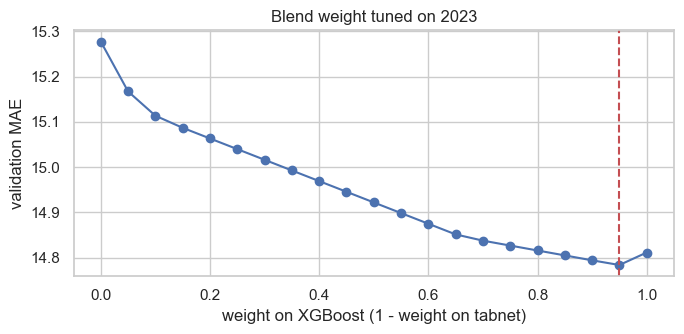

,model,MAE,RMSE,R2,ROC_AUC,F1,Precision,Recall,Balanced_Accuracy
0,Baseline: median / total_x rule,18.619,30.059,-0.112,0.835,0.839,0.773,0.917,0.639
1,XGBoost,20.099,27.797,0.049,0.823,0.784,0.888,0.701,0.746
2,tabnet,18.642,25.276,0.214,0.767,0.789,0.809,0.770,0.670
3,Blend (0.95 XGB + 0.05 tabnet),19.962,27.566,0.065,0.776,0.789,0.809,0.770,0.670


In [2]:
P = pd.read_csv("data/interim/model_predictions.csv")
pv, pt = P[P.split == "val"].reset_index(drop=True), P[P.split == "test"].reset_index(drop=True)
yv, yt = va.set_index("ipo_id").loc[pv.ipo_id, "listing_gain_pct"].values, te.set_index("ipo_id").loc[pt.ipo_id, "listing_gain_pct"].values
cv_, ct = (yv > 0).astype(int), (yt > 0).astype(int)
best_dl = min(["tabnet", "fastai"], key=lambda m: reg_metrics(yv, pv[m])["MAE"])
print("best deep model on validation:", best_dl)

ws = np.linspace(0, 1, 21)
curve = [reg_metrics(yv, w * pv.xgb + (1 - w) * pv[best_dl])["MAE"] for w in ws]
w_best = float(ws[int(np.argmin(curve))])
curve_p = [clf_metrics(cv_, w * pv.xgb_p + (1 - w) * pv[f"{best_dl}_p"])["ROC_AUC"] for w in ws]
wp_best = float(ws[int(np.argmax(curve_p))])
print(f"best weight on XGBoost: regression {w_best:.2f}, classification {wp_best:.2f}")

plt.figure(figsize=(7, 3.5)); plt.plot(ws, curve, marker="o"); plt.axvline(w_best, ls="--", c="r")
plt.xlabel(f"weight on XGBoost (1 - weight on {best_dl})"); plt.ylabel("validation MAE"); plt.title("Blend weight tuned on 2023")
plt.tight_layout(); plt.savefig(FIG / "blend_weight.png", dpi=120); plt.show()

med = trva.listing_gain_pct.median()
blend_rows = []
# each model's up/down cut-off is chosen on validation (Youden's J), since the scores are not on the same scale
CLS_COLS = ("ROC_AUC", "F1", "Precision", "Recall", "Balanced_Accuracy")
for name, r, p_val, p in [
    ("Baseline: median / total_x rule", np.full(len(yt), med), None, None),
    ("XGBoost", pt.xgb, pv.xgb_p, pt.xgb_p),
    (best_dl, pt[best_dl], pv[f"{best_dl}_p"], pt[f"{best_dl}_p"]),
    (f"Blend ({w_best:.2f} XGB + {1 - w_best:.2f} {best_dl})", w_best * pt.xgb + (1 - w_best) * pt[best_dl],
     wp_best * pv.xgb_p + (1 - wp_best) * pv[f"{best_dl}_p"], wp_best * pt.xgb_p + (1 - wp_best) * pt[f"{best_dl}_p"]),
]:
    row = {"model": name, **reg_metrics(yt, r)}
    if p is not None:
        row.update({k: v for k, v in clf_metrics(ct, p, youden_threshold(cv_, p_val)).items() if k in CLS_COLS})
    blend_rows.append(row)
base_cls = meta["baseline_test_metrics"]
blend_rows[0].update({k: base_cls[k] for k in CLS_COLS})
blend = pd.DataFrame(blend_rows).round(3)
blend

**What the blend table says.** TabNet is the better deep model on 2023, but the validation curve barely moves: the best weight is 0.95 on XGBoost, which improves 2023 MAE by only 0.03 points. For the up/down score the validation-best weight is 0.10 on XGBoost, and that blend does worse on test (ROC-AUC 0.78 vs 0.82), a reminder that 58 validation IPOs is a noisy place to tune a weight.

Is the blend's improvement (if any) bigger than noise? Paired bootstrap over test IPOs:

In [3]:
rng = np.random.default_rng(SEED)
e_x = np.abs(yt - pt.xgb.values)
e_b = np.abs(yt - (w_best * pt.xgb + (1 - w_best) * pt[best_dl]).values)
boot = [np.mean(e_x[i] - e_b[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"MAE(XGB) - MAE(blend) = {e_x.mean() - e_b.mean():.3f}  95% CI [{lo:.3f}, {hi:.3f}]")
blend_clear_win = lo > 0
print("blend clearly better than XGBoost alone:", blend_clear_win)

MAE(XGB) - MAE(blend) = 0.137  95% CI [0.075, 0.195]
blend clearly better than XGBoost alone: True


The test gain is real but tiny (about 0.14 MAE points, 95% CI roughly 0.07 to 0.20). Statistically detectable is not the same as worth shipping: the decision in section 4 is made on the validation year, not on this test check.

## 2. Interpretability with the production XGBoost model

| | Global (whole model) | Local (one prediction) |
|---|---|---|
| **Model-specific** | XGBoost gain / weight / cover; mean \|TreeSHAP\| | TreeSHAP values for one IPO |
| **Model-agnostic** | Permutation importance | Permutation-SHAP (black-box) for one IPO |

TreeSHAP values come straight from XGBoost (`pred_contribs=True`), which computes exact SHAP values
for tree ensembles, including its native categorical splits.

In [4]:
booster = xgb.Booster(); booster.load_model("models/xgb_reg.json")
Xte = F.engineer(te)
dm = xgb.DMatrix(Xte, enable_categorical=True)
contrib = booster.predict(dm, pred_contribs=True)
sv, base_value = contrib[:, :-1], contrib[0, -1]
pred_te = booster.predict(dm)
assert np.allclose(sv.sum(1) + base_value, pred_te, atol=1e-3), "SHAP values must add up to the prediction"

disp = Xte.copy()
disp["exchange"] = disp.exchange.cat.codes; disp["sector"] = disp.sector.cat.codes
expl = shap.Explanation(values=sv, base_values=np.full(len(sv), base_value), data=disp.values, feature_names=list(Xte.columns))
print(f"base value (average prediction) {base_value:.2f}%")

base value (average prediction) 9.07%


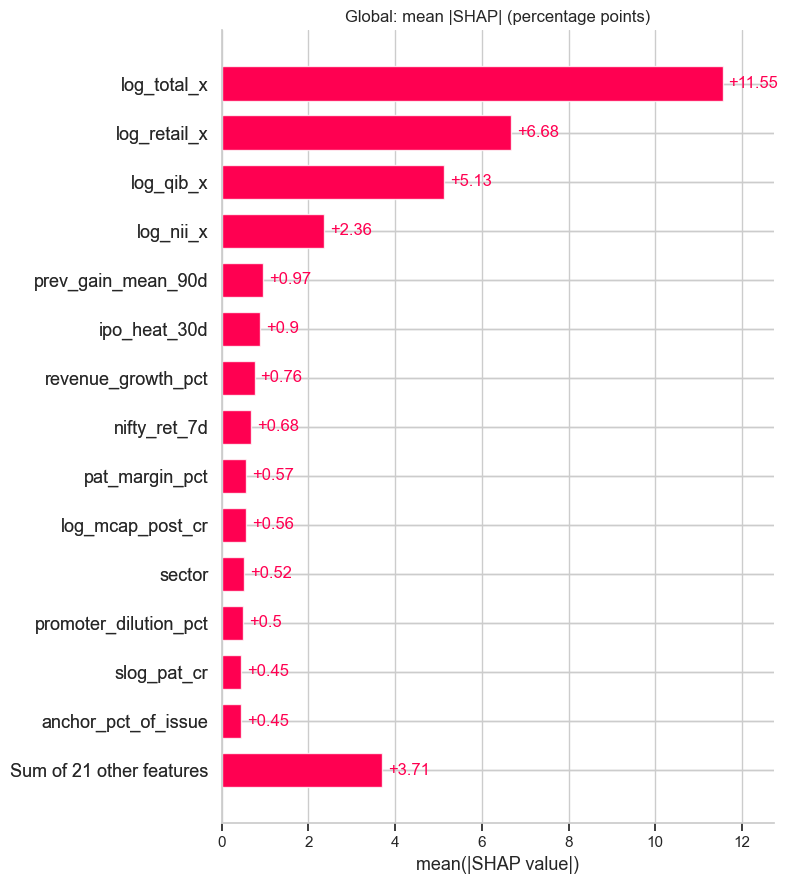

In [5]:
shap.plots.bar(expl, max_display=15, show=False); plt.title("Global: mean |SHAP| (percentage points)")
plt.tight_layout(); plt.savefig(FIG / "shap_bar.png", dpi=120, bbox_inches="tight"); plt.show()

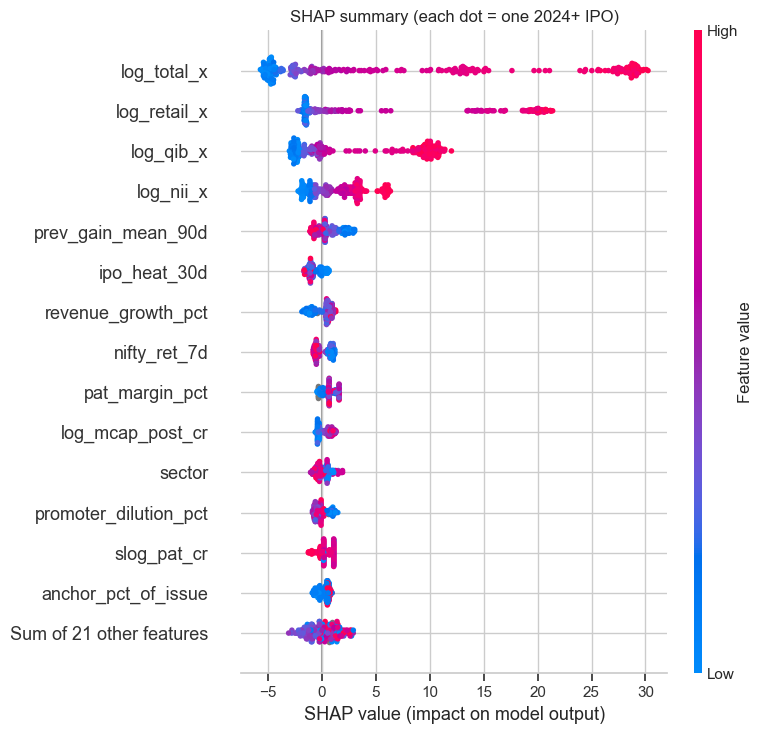

In [6]:
shap.plots.beeswarm(expl, max_display=15, show=False); plt.title("SHAP summary (each dot = one 2024+ IPO)")
plt.tight_layout(); plt.savefig(FIG / "shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

**Global reading.** Subscription is almost the whole model: total, retail, QIB and NII multiples are the top four by mean |SHAP| and dwarf everything else (each of the rest moves the forecast by about 1 point on average). The direction is monotone and as expected: low subscription (blue) pushes the forecast 2 to 5 points below the base value, very high subscription (red) pushes it up by 10 to 30 points.

Two market features point the "wrong" way: a high average gain of the IPOs listed in the previous 90 days (`prev_gain_mean_90d`) and many recent IPOs (`ipo_heat_30d`) both lower the forecast slightly. Their effect is small (under 3 points) and should not be read as causal; a hot IPO market also brings weaker issues, and these features have the largest train/test drift in notebook 01.

### Dependence plots: qib_x, retail_x, issue_size_cr, India VIX
x-axis is on the log scale the model sees (log1p of the multiple / size).

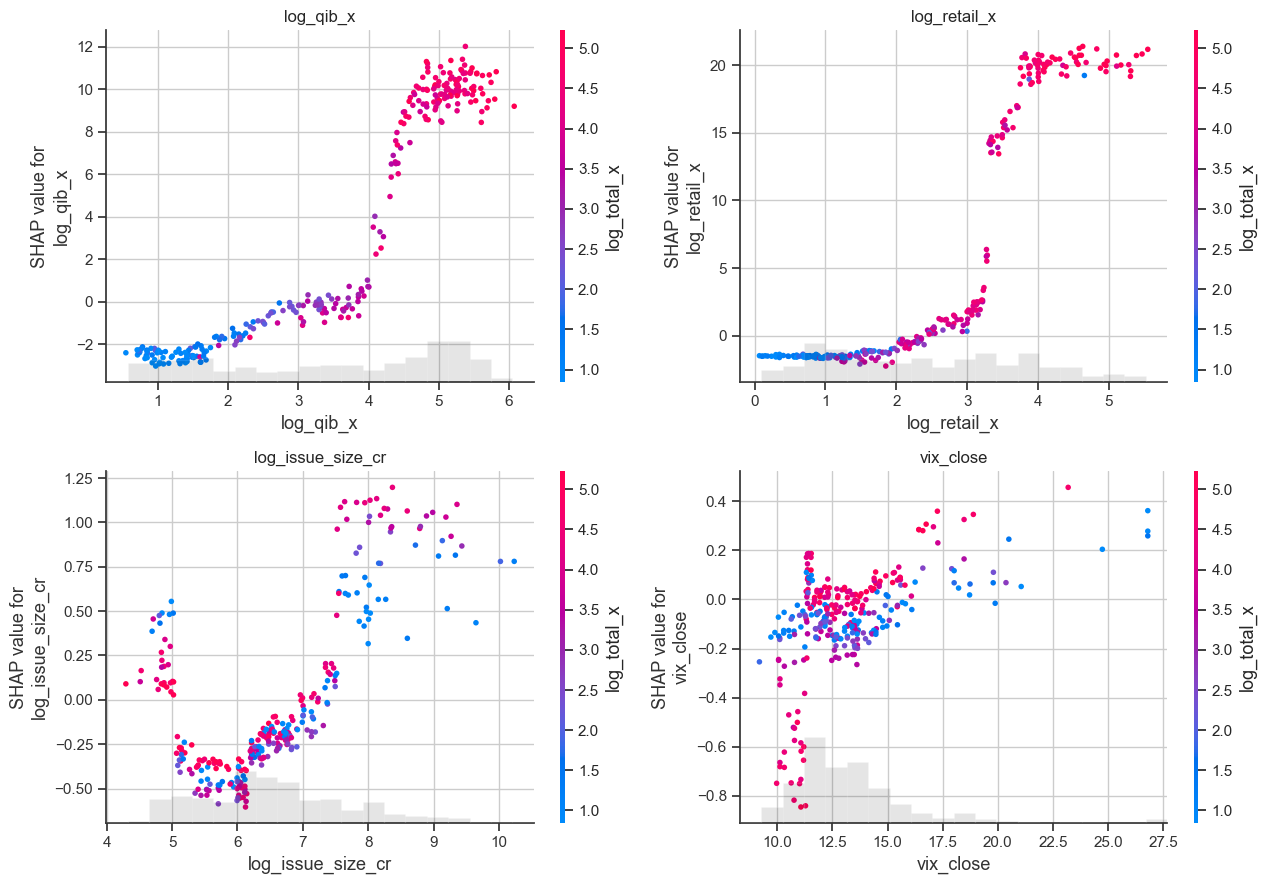

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, f in zip(axes.ravel(), ["log_qib_x", "log_retail_x", "log_issue_size_cr", "vix_close"]):
    shap.plots.scatter(expl[:, f], color=expl[:, "log_total_x"] if f != "log_total_x" else None, ax=ax, show=False)
    ax.set_title(f)
plt.tight_layout(); plt.savefig(FIG / "shap_dependence.png", dpi=120, bbox_inches="tight"); plt.show()

**Dependence plots** (x is log1p of the value):
* **QIB:** flat below about 50x (log 4), then a steep step to +8 to +12 points once QIB demand passes roughly 70 to 100x. Institutions crowding in is the strongest single signal.
* **Retail:** almost no effect below about 20x (log 3), then a jump to +15 to +20 points above roughly 25 to 50x. Strong retail demand is the second big signal, and also the riskiest (see the "surprise" IPO below).
* **Issue size:** small effect (within about ±1 point). Mid-sized issues (roughly ₹150 to 400 Cr) get a small negative push, very small and very large issues a small positive one.
* **India VIX:** the model barely uses it (under 1 point either way). Calm markets (VIX 10 to 11) are slightly negative. VIX has little information beyond subscription, which already reacts to market mood.

### Local: three interesting IPOs
* **big winner**: the highest actual listing gain in the test years
* **big loser**: the lowest actual listing gain
* **surprise**: the largest miss where the model got the direction wrong

big winner: Vibhor Steel Tubes Ltd. (20 Feb 2024) actual 181.5% predicted 73.6%


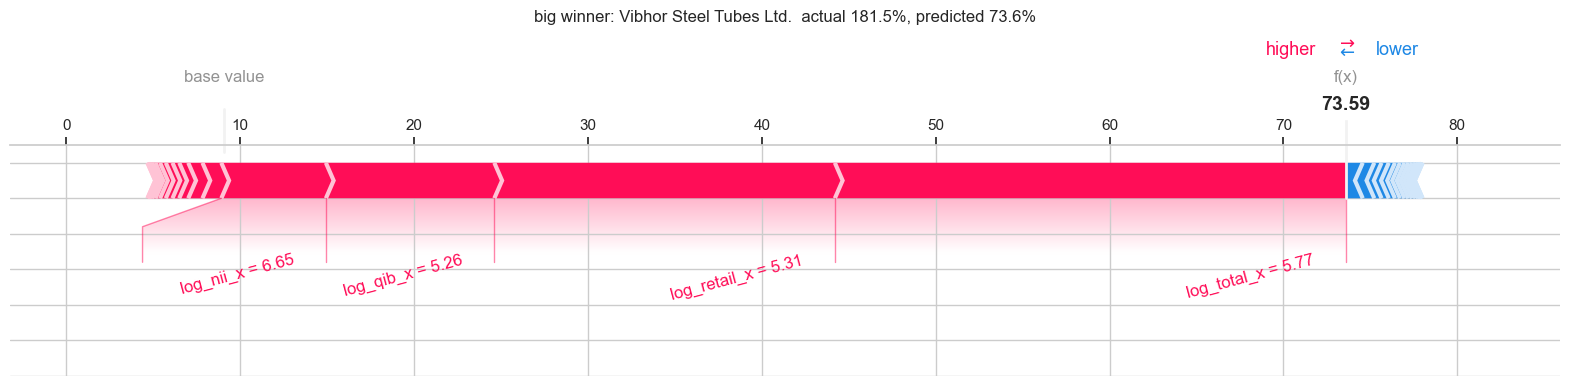

big loser: Om Freight Forwarders Ltd. (08 Oct 2025) actual -39.6% predicted -0.4%


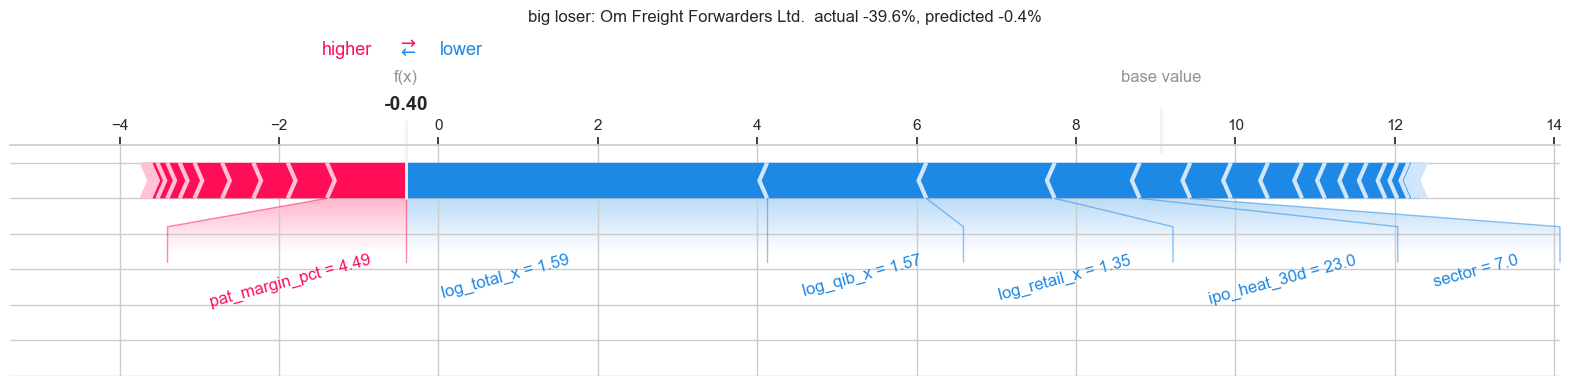

surprise: Shree Ram Twistex Ltd. (02 Mar 2026) actual -34.6% predicted 37.3%


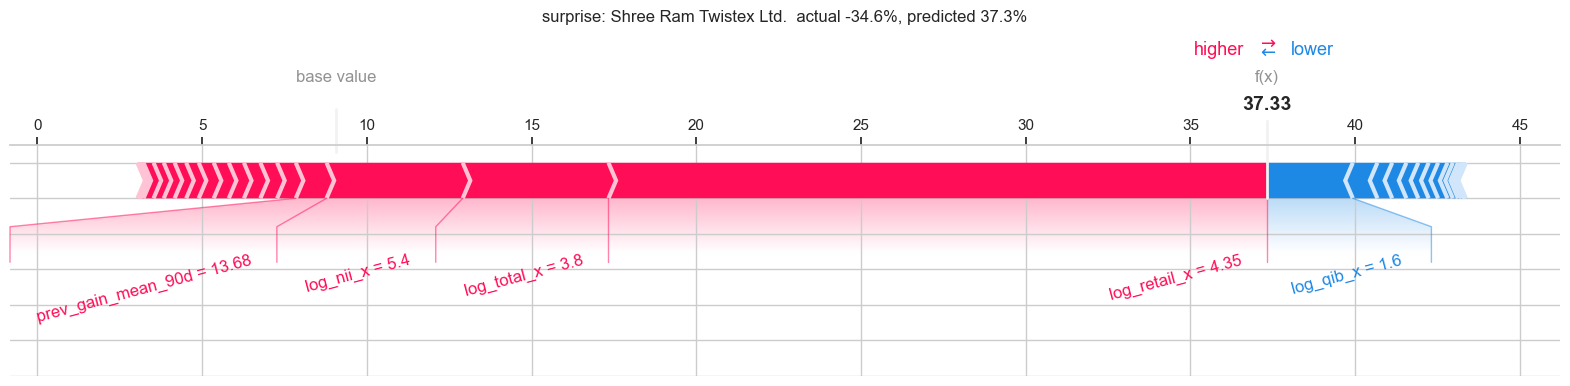

In [8]:
t = te.reset_index(drop=True).assign(pred=pred_te, err=lambda d: d.listing_gain_pct - d.pred)
picks = {
    "big winner": int(t.listing_gain_pct.idxmax()),
    "big loser": int(t.listing_gain_pct.idxmin()),
    "surprise": int(t[(t.pred > 0) != (t.listing_gain_pct > 0)].err.abs().idxmax()),
}
local_export = []
for label, i in picks.items():
    r = t.loc[i]
    print(f"{label}: {r.company} ({r.listing_date:%d %b %Y}) actual {r.listing_gain_pct:.1f}% predicted {r.pred:.1f}%")
    shap.plots.force(base_value, sv[i], np.round(disp.iloc[i].values.astype(float), 2), feature_names=list(Xte.columns),
                     matplotlib=True, show=False, text_rotation=15)
    plt.title(f"{label}: {r.company}  actual {r.listing_gain_pct:.1f}%, predicted {r.pred:.1f}%", y=1.5)
    plt.savefig(FIG / f"shap_force_{label.replace(' ', '_')}.png", dpi=120, bbox_inches="tight"); plt.show()
    top = np.argsort(-np.abs(sv[i]))[:8]
    local_export.append({"label": label, "company": r.company, "listing_date": f"{r.listing_date:%Y-%m-%d}", "actual": float(r.listing_gain_pct),
                         "predicted": float(r.pred), "base": float(base_value),
                         "top": [{"feature": Xte.columns[j], "shap": float(sv[i, j])} for j in top]})

**The three IPOs.**
* **Big winner, Vibhor Steel Tubes (Feb 2024): actual +181.5%, predicted +73.6%.** 320x total subscription (QIB 191x, retail 202x). Every subscription feature pushes up (+29, +20, +10, +6). The model got the direction and called it a big winner, but trees cannot extrapolate beyond the highest leaf values they have seen, so extreme listings are always under-predicted.
* **Big loser, Om Freight Forwarders (Oct 2025): actual -39.6%, predicted -0.4%.** Weak demand everywhere (3.9x total, QIB 3.8x, retail 2.8x). The model correctly sees a weak issue but its floor is close to 0%: few training IPOs lost this much, so the loss tail is shrunk.
* **Surprise, Shree Ram Twistex (Mar 2026): actual -34.6%, predicted +37.3%.** Retail 77x and NII 220x, but QIB only 3.9x. Retail alone contributed +20 points. The grey market disagreed sharply: GMP was -27% the evening before listing. When retail and HNI money is euphoric but institutions stay away, the model is overconfident.

Model-agnostic local check: a black-box Permutation explainer on the "surprise" IPO, which only calls
`predict`. If it agrees with TreeSHAP, the explanation isn't an artefact of the tree algorithm.

In [9]:
cols = list(Xte.columns)
def f_black_box(A):
    D = pd.DataFrame(A, columns=cols)
    for c in F.CATEGORICAL:
        D[c] = pd.Categorical.from_codes(D[c].round().astype(int).clip(0, len(F.CATEGORIES[c]) - 1), categories=F.CATEGORIES[c])
    for c in F.numeric_names():
        D[c] = D[c].astype(float)
    return booster.predict(xgb.DMatrix(D, enable_categorical=True))

bg_disp = F.engineer(trva).assign(exchange=lambda d: d.exchange.cat.codes, sector=lambda d: d.sector.cat.codes)
bg = shap.maskers.Independent(bg_disp.fillna(bg_disp.median()).sample(100, random_state=SEED).values)
pe = shap.PermutationExplainer(f_black_box, bg)
i = picks["surprise"]
pv_local = pe(disp.iloc[[i]].values.astype(float), max_evals=2 * len(cols) + 1 + 400).values[0]
cmp_local = pd.DataFrame({"TreeSHAP": sv[i], "Permutation (agnostic)": pv_local}, index=cols)
cmp_local = cmp_local.reindex(cmp_local.TreeSHAP.abs().sort_values(ascending=False).index).head(10).round(2)
print("Spearman between the two local explanations (all features):",
      round(stats.spearmanr(sv[i], pv_local).statistic, 3))
cmp_local

Spearman between the two local explanations (all features): 0.852


,TreeSHAP,Permutation (agnostic)
log_retail_x,19.99,18.64
log_total_x,4.43,-0.26
log_nii_x,4.13,2.86
log_qib_x,-2.60,-4.05
prev_gain_mean_90d,0.93,1.05
revenue_growth_pct,-0.75,-0.90
log_snii_x,0.57,0.61
log_price_band_upper,0.51,0.52
nifty_ret_7d,0.50,0.61
promoter_post_pct,0.46,0.41


The black-box explainer agrees with TreeSHAP (Spearman 0.85 across all features; retail +18.7 vs +20.0 points). The one notable difference is `log_total_x` (+4.4 TreeSHAP vs about 0 permutation): total subscription is strongly correlated with retail and NII, and the two methods split shared credit among correlated features differently.

### Built-in importance (gain, weight, cover) vs SHAP vs permutation

In [10]:
imp = pd.DataFrame({k: pd.Series(booster.get_score(importance_type=k)) for k in ("gain", "weight", "cover", "total_gain")}).reindex(cols).fillna(0)
imp["mean_abs_SHAP"] = np.abs(sv).mean(0)

class _Wrap:  # sklearn-style wrapper so permutation_importance can call predict on the booster
    def fit(self, X, y): return self
    def predict(self, X): return booster.predict(xgb.DMatrix(X, enable_categorical=True))
perm = permutation_importance(_Wrap(), Xte, te.listing_gain_pct.values, scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEED)
imp["permutation_MAE_increase"] = perm.importances_mean
ranks = imp.rank(ascending=False).astype(int)
imp_view = imp.round(2).join(ranks.add_suffix("_rank")).sort_values("mean_abs_SHAP", ascending=False)
imp_view.head(15)

,gain,weight,cover,total_gain,mean_abs_SHAP,permutation_MAE_increase,gain_rank,weight_rank,cover_rank,total_gain_rank,mean_abs_SHAP_rank,permutation_MAE_increase_rank
log_total_x,3482.23,120.0,101.11,417868.16,11.55,1.70,1,1,3,1,1,1
log_retail_x,1977.03,71.0,117.38,140368.94,6.68,-0.56,4,3,1,3,2,35
log_qib_x,2140.58,71.0,92.71,151981.20,5.13,0.17,3,3,8,2,3,2
log_nii_x,2823.18,39.0,93.83,110103.88,2.36,-0.46,2,6,7,4,4,34
prev_gain_mean_90d,444.45,82.0,88.02,36445.29,0.97,-0.14,14,2,12,5,5,32
ipo_heat_30d,390.60,26.0,66.31,10155.54,0.90,0.03,19,10,21,9,6,8
revenue_growth_pct,440.30,28.0,84.47,12328.43,0.76,0.10,15,8,13,8,7,3
nifty_ret_7d,309.21,30.0,93.83,9276.21,0.68,0.00,29,7,6,10,8,13
pat_margin_pct,383.83,13.0,51.53,4989.80,0.57,-0.00,22,18,25,20,9,21
log_mcap_post_cr,469.27,14.0,74.68,6569.84,0.56,0.09,13,17,17,16,10,6


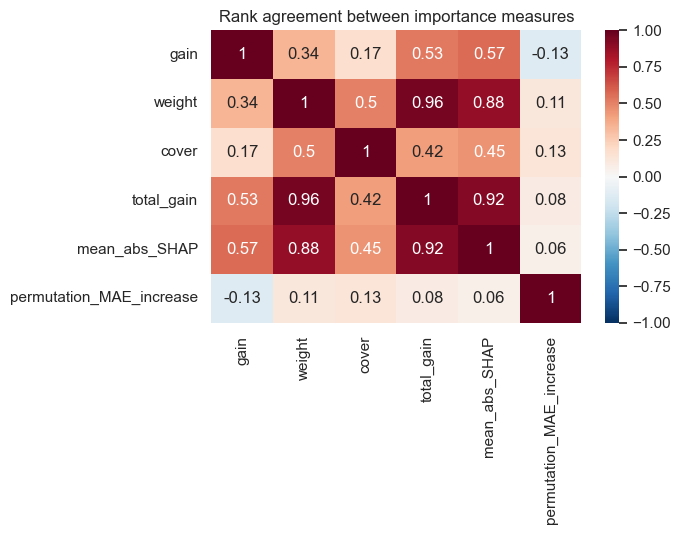

In [11]:
rank_corr = imp.corr(method="spearman").round(2)
plt.figure(figsize=(7, 5.5)); sns.heatmap(rank_corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Rank agreement between importance measures"); plt.tight_layout(); plt.savefig(FIG / "importance_agreement.png", dpi=120); plt.show()

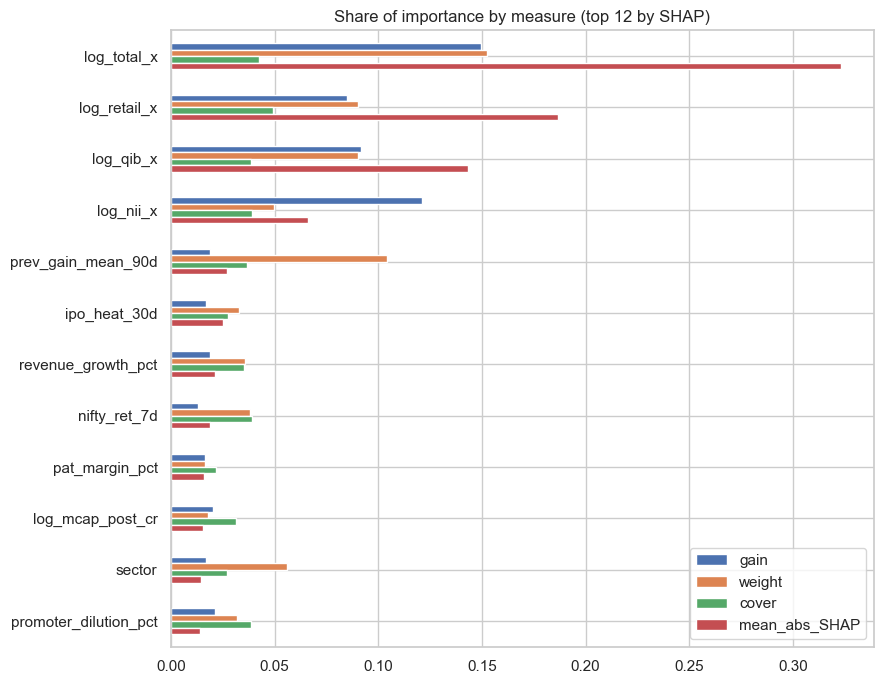

features 'weight' rates much higher than SHAP does: {'vix_close': -16, 'fresh_issue_pct': -8, 'anchor_pct_of_issue': -6, 'sector': -6, 'nifty_ret_30d': -5}
features SHAP rates much higher than 'weight' does: {'log_min_investment': 5, 'log_mcap_post_cr': 7, 'log_snii_x': 9, 'pat_margin_pct': 9, 'slog_pat_cr': 10}


In [12]:
norm = imp[["gain", "weight", "cover", "mean_abs_SHAP"]] / imp[["gain", "weight", "cover", "mean_abs_SHAP"]].sum()
norm.loc[norm.mean_abs_SHAP.sort_values(ascending=False).index[:12]].plot.barh(figsize=(9, 7)).invert_yaxis()
plt.title("Share of importance by measure (top 12 by SHAP)"); plt.tight_layout(); plt.savefig(FIG / "importance_compare.png", dpi=120); plt.show()

disagree = (ranks["weight"] - ranks["mean_abs_SHAP"]).sort_values()
print("features 'weight' rates much higher than SHAP does:", disagree.head(5).to_dict())
print("features SHAP rates much higher than 'weight' does:", disagree.tail(5).to_dict())

**Where the importance measures disagree.** All measures agree that total subscription is number one. `weight` (how often a feature is split on) is the least trustworthy: it ranks VIX, fresh-issue share, anchor share, sector and Nifty 30-day return much higher than SHAP, because continuous features with many distinct values get split on often for tiny gains. `gain` per split over-rewards features used rarely but at a lucky split (`slog_pat_cr` rank 7 by gain, 13 by SHAP). Permutation importance on test is close to zero or negative for most features: under the 2024+ regime shift, shuffling one feature hardly hurts a model that already over-predicts, and for correlated subscription features shuffling one leaves the others carrying the signal. SHAP is the measure used in the app because it is consistent, additive per IPO and has a direction.

## 3. GMP experiment: does subscription data add value beyond the grey-market premium?

GMP (InvestorGain, last public reading dated **before** listing day) only exists from 2020, so this uses
a smaller sample: fit on 2020–2023, test on 2024+. Same XGBoost settings; only the inputs change.

F1 is not reported here: at a 0.5 cut-off every classifier in this experiment calls every IPO "up", and this sample has no separate validation year to choose a better cut-off on.

In [13]:
g = df[df.gmp_pct.notna() & (df.listing_year >= 2020)].copy()
g_tr, g_te = g[g.listing_year <= 2023], g[g.listing_year >= 2024]
print(f"GMP sample: {len(g)} IPOs ({len(g_tr)} fit / {len(g_te)} test); GMP coverage of all 2020+ IPOs: "
      f"{df[df.listing_year >= 2020].gmp_pct.notna().mean() * 100:.0f}%")
print("Spearman(GMP %, listing gain %) on test:", round(stats.spearmanr(g_te.gmp_pct, g_te.listing_gain_pct).statistic, 3))

rp, cp = _params()
sub_cols = ["log_qib_x", "log_nii_x", "log_bnii_x", "log_snii_x", "log_retail_x", "log_employee_x", "log_total_x"]

def run(cols_fn, label):
    A, B = cols_fn(g_tr), cols_fn(g_te)
    m = fit_xgb(rp, A, g_tr.listing_gain_pct, n_estimators=300, kind="reg")
    c = fit_xgb(cp, A, g_tr.listed_positive.astype(int), n_estimators=300, kind="clf")
    return {"inputs": label, **reg_metrics(g_te.listing_gain_pct, m.predict(B)),
            **{k: v for k, v in clf_metrics(g_te.listed_positive, c.predict_proba(B)[:, 1]).items() if k == "ROC_AUC"}}

gmp_only = lambda d: d[["gmp_pct"]]
gmp_sub = lambda d: F.engineer(d)[sub_cols].assign(gmp_pct=d.gmp_pct.values)
all_no_gmp = lambda d: F.engineer(d)
all_gmp = lambda d: F.engineer(d).assign(gmp_pct=d.gmp_pct.values)
naive_gmp = {"inputs": "GMP % taken literally as the forecast", **reg_metrics(g_te.listing_gain_pct, g_te.gmp_pct),
             **{k: v for k, v in clf_metrics(g_te.listed_positive, (g_te.gmp_pct > 0).astype(float)).items() if k == "ROC_AUC"}}
naive_gmp["ROC_AUC"] = clf_metrics(g_te.listed_positive, g_te.gmp_pct.rank(pct=True))["ROC_AUC"]
gmp_table = pd.DataFrame([
    naive_gmp,
    run(gmp_only, "XGBoost: GMP only"),
    run(lambda d: F.engineer(d)[sub_cols], "XGBoost: subscription only"),
    run(gmp_sub, "XGBoost: GMP + subscription"),
    run(all_no_gmp, "XGBoost: all features, no GMP"),
    run(all_gmp, "XGBoost: all features + GMP"),
]).round(3)
gmp_table

GMP sample: 449 IPOs (164 fit / 285 test); GMP coverage of all 2020+ IPOs: 97%
Spearman(GMP %, listing gain %) on test: 0.873


,inputs,MAE,RMSE,R2,ROC_AUC
0,GMP % taken literally as the forecast,8.762,13.434,0.780,0.891
1,XGBoost: GMP only,9.453,14.079,0.758,0.870
2,XGBoost: subscription only,19.978,27.887,0.052,0.813
3,XGBoost: GMP + subscription,10.008,14.669,0.738,0.850
4,"XGBoost: all features, no GMP",19.623,27.033,0.109,0.811
5,XGBoost: all features + GMP,10.322,14.829,0.732,0.859


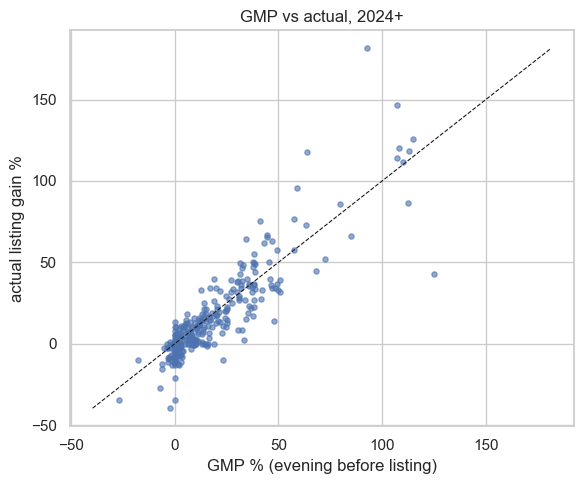

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(g_te.gmp_pct, g_te.listing_gain_pct, s=14, alpha=0.6)
lim = [min(g_te.gmp_pct.min(), g_te.listing_gain_pct.min()), max(g_te.gmp_pct.max(), g_te.listing_gain_pct.max())]
ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlabel("GMP % (evening before listing)"); ax.set_ylabel("actual listing gain %")
ax.set_title("GMP vs actual, 2024+"); plt.tight_layout(); plt.savefig(FIG / "gmp_vs_actual.png", dpi=120); plt.show()

**GMP answer: no, subscription does not add value once you have GMP.** GMP taken literally as the forecast is the best model of all (test MAE 8.8, R² 0.78, ROC-AUC 0.89; Spearman 0.87 with the actual gain). Every XGBoost model with GMP lands at MAE 9.5 to 10.3, and adding subscription or all other features to GMP makes it slightly *worse*, not better. Without GMP the best we can do is MAE about 19.6. The grey market already prices in subscription, anchor demand and market mood, and it is read hours before listing, after the last subscription numbers are known.

Why GMP is still not in the production model: it is unofficial, unregulated and not SEBI-recognised, it is easy to manipulate, the public preview only has recent readings, and the course question is what can be learned from official pre-listing data. The app therefore predicts from official data only, and the README states plainly that a single number from the grey market beats it.

## 4. Final decision on the production model

In [15]:
# decided on the validation year, not on test: the blend must cut 2023 MAE by at least half a point to be
# worth shipping a second (PyTorch) model and losing exact per-IPO TreeSHAP in the API
val_gain = curve[-1] - min(curve)   # curve[-1] is weight 1.0 = XGBoost alone
choice = "blend" if val_gain >= 0.5 else "XGBoost"
print(f"blend improves 2023 MAE by {val_gain:.2f} points -> production model: {choice}")
print(f"(test check, not used for the decision: blend changes test MAE by {e_b.mean() - e_x.mean():+.2f}, 95% CI of the gain [{lo:.2f}, {hi:.2f}])")
export = {
    "blend": blend.to_dict(orient="records"), "blend_weight_xgb": w_best, "best_dl": best_dl,
    "blend_ci": [float(lo), float(hi)], "blend_clear_win": bool(blend_clear_win), "blend_val_gain": float(val_gain), "production_choice": choice,
    "shap_global": [{"feature": c, "mean_abs_shap": float(v)} for c, v in imp.mean_abs_SHAP.sort_values(ascending=False).items()],
    "importance": imp_view.reset_index(names="feature").to_dict(orient="records"),
    "local": local_export, "gmp": gmp_table.to_dict(orient="records"),
    "gmp_n": {"fit": int(len(g_tr)), "test": int(len(g_te))},
}
(OUT / "explain.json").write_text(json.dumps(export, default=float))
print("wrote", OUT / "explain.json")

blend improves 2023 MAE by 0.03 points -> production model: XGBoost
(test check, not used for the decision: blend changes test MAE by -0.14, 95% CI of the gain [0.07, 0.20])
wrote frontend\public\insights\explain.json


## Summary

* **Production model: XGBoost alone.** The blend's validation gain (0.03 MAE points) is far below the half-point bar that would justify shipping a PyTorch model and giving up exact per-IPO TreeSHAP in the API.
* **Honest test result (2024+, 290 IPOs):** MAE 20.1 points against 18.6 for always predicting the median, so on the average miss the model does not beat the naive baseline. It is better on RMSE (27.8 vs 30.1) and R² (0.05 vs -0.11), i.e. on the big listings, and it ranks IPOs well for up/down (ROC-AUC 0.82, balanced accuracy 0.75 vs 0.64 for the subscription rule).
* **Why:** the subscription-to-gain relationship shifted. Median total subscription went from about 9x (2012–2022) to about 34x (2023 onward) without gains rising to match, so the model over-predicts by about 12 points on average in the test years.
* **What drives the forecast:** QIB and retail subscription, each with a clear threshold (QIB past about 70x, retail past about 25x). Market-level features matter little.
* **The grey-market premium alone beats everything here** (MAE 8.8). Official pre-listing data does not add to it.